# # Lapis 1 — B0 (aturan v1), B1, dan B2 LightGBM
Notebook tipis: semua angka dibaca dari `ml/reports/tables/` yang dihasilkan skrip (`scripts/e1_b0.py`, `train_l1_baselines.py`, `train_l1_lgbm.py`, `train_l1_lgbm_seeds.py`, `l1_select.py`, `export_l1.py`). Semua hasil di sini adalah **CV (80% siswa)**; test set belum dibuka.

In [1]:
import pandas as pd
from IPython.display import Image, display
from remediaide_ml.paths import TABLES, FIGURES, RUNS
pd.set_option("display.precision", 4)

# ## E1 — aturan CRI v1 (B0) terhadap kuadran masa depan

In [2]:
pd.read_csv(TABLES / 'E1_b0_cv.csv')

,metrik,nilai,ci_lo,ci_hi,split,n_baris,run
0,tingkat salah kelompok (4 kelas),0.4501,0.4404,0.4593,CV (80% siswa),217480,20261118-2156_e1_b0
1,macro-F1 (4 kelas),0.4116,0.4034,0.4193,CV (80% siswa),217480,20261118-2156_e1_b0
2,% 'Paham' B0 yang belum tuntas berikutnya,0.2819,0.2705,0.2940,CV (80% siswa),217480,20261118-2156_e1_b0
3,% 'Miskonsepsi' B0 yang tuntas berikutnya,0.5069,0.4953,0.5186,CV (80% siswa),217480,20261118-2156_e1_b0
4,error biner butuh_remediasi,0.3667,0.3629,0.3704,CV (80% siswa),912731,20261118-2156_e1_b0


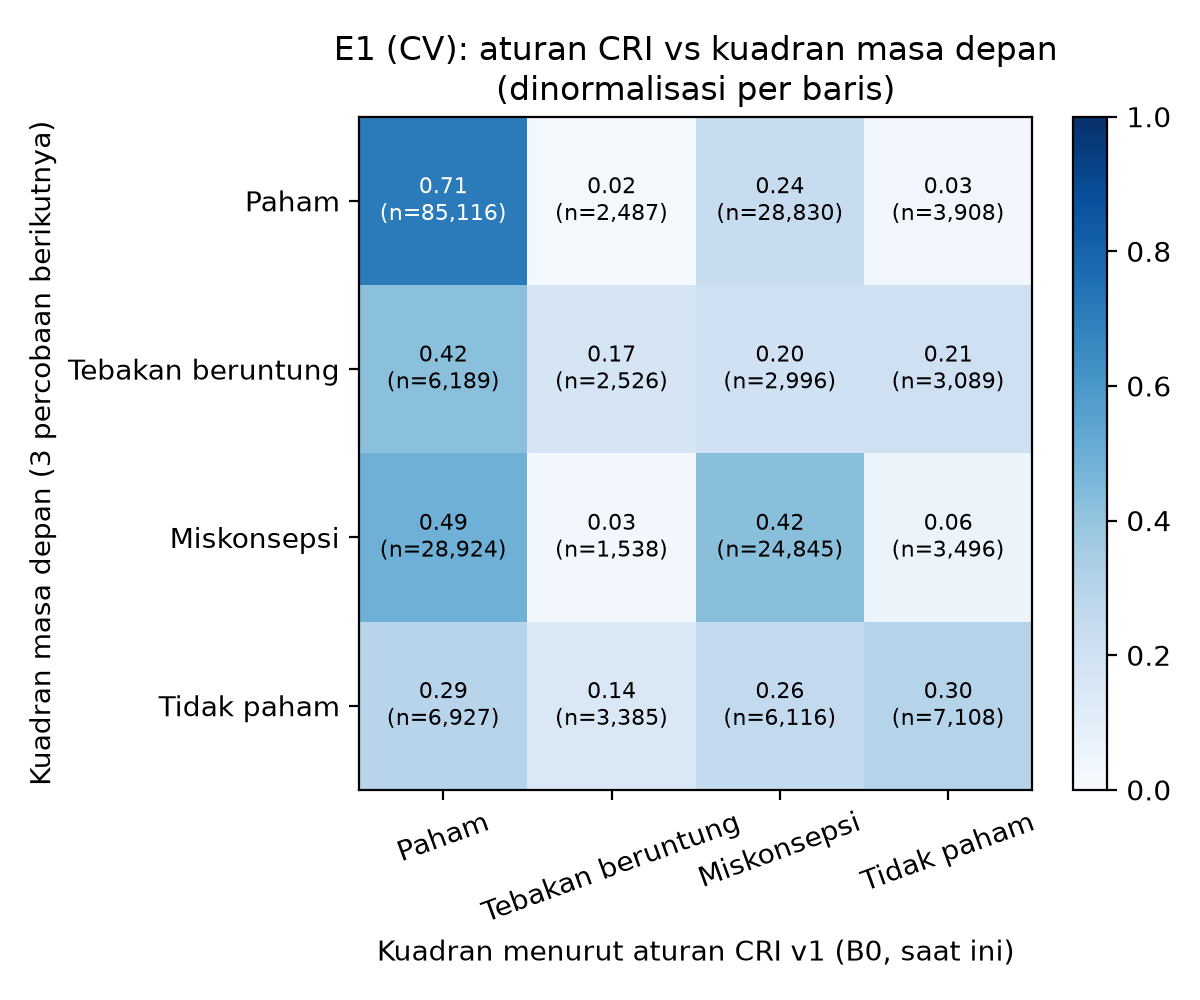

In [3]:
display(Image(FIGURES / 'E1_confusion_b0_cv.png', width=520))

# ## Ringkasan CV Lapis 1 (B0, B1, LightGBM, CO-KT)

In [4]:
pd.read_csv(TABLES / 'L1_cv_summary.csv')

,framing,model,metric,value,ci_lo,ci_hi,sumber,produksi
0,a,B1a (akurasi saja),auc,0.6732,0.6698,0.6762,L1_b0_b1_cv.csv,False
1,a,B1b (akurasi + keyakinan),auc,0.7439,0.7408,0.7466,L1_b0_b1_cv.csv,False
2,b,B1a (akurasi saja),auc,0.5576,0.5557,0.5593,L1_b0_b1_cv.csv,False
3,b,B1b (akurasi + keyakinan),auc,0.7358,0.7314,0.7395,L1_b0_b1_cv.csv,False
4,b,B0 aturan v1,auc,0.6329,0.6294,0.6358,L1_b0_b1_cv.csv,False
5,b,B0 aturan v1,macro_f1,0.4116,0.4034,0.4193,L1_b0_b1_cv.csv,False
6,b,B0 aturan v1,misgroup,0.4501,0.4404,0.4593,L1_b0_b1_cv.csv,False
7,b,B1a (akurasi saja),macro_f1,0.1781,0.1751,0.1812,L1_b0_b1_cv.csv,False
8,b,B1a (akurasi saja),misgroup,0.4467,0.4318,0.4612,L1_b0_b1_cv.csv,False
9,b,B1b (akurasi + keyakinan),macro_f1,0.3788,0.3711,0.3862,L1_b0_b1_cv.csv,False


# ## E2 — ablation fitur LightGBM (S0 → S6)

In [5]:
pd.read_csv(TABLES / 'E2_ablation_cv.csv')

,tahap,macro_f1,macro_f1_lo,macro_f1_hi,misgroup,misgroup_lo,misgroup_hi,auc_bin,auc_bin_lo,auc_bin_hi,run,delong_p_vs_prev,delong_p_holm
0,S0_cur_correct,0.1781,0.1751,0.1812,0.4467,0.4318,0.4612,0.6309,0.6257,0.6358,20261118-2205_l1_lgbm,NaN,NaN
1,S1_keyakinan,0.2913,0.2847,0.2979,0.4275,0.4150,0.4395,0.6517,0.6466,0.6561,20261118-2205_l1_lgbm,0.0000e+00,0.0000e+00
2,S2_riwayat_benar,0.4002,0.3919,0.4085,0.3879,0.3771,0.3977,0.7776,0.7732,0.7818,20261118-2205_l1_lgbm,0.0000e+00,0.0000e+00
3,S3_riwayat_keyakinan,0.4398,0.4272,0.4514,0.3776,0.3674,0.3873,0.7765,0.7718,0.7806,20261118-2205_l1_lgbm,9.3953e-41,1.8791e-40
4,S4_kesulitan,0.4620,0.4505,0.4733,0.3614,0.3515,0.3704,0.7970,0.7926,0.8003,20261118-2205_l1_lgbm,0.0000e+00,0.0000e+00
5,S5_opsi,0.4629,0.4511,0.4743,0.3611,0.3513,0.3699,0.7976,0.7933,0.8009,20261118-2205_l1_lgbm,8.8784e-33,8.8784e-33
6,S6_waktu,0.4647,0.4531,0.4765,0.3593,0.3493,0.3684,0.8004,0.7962,0.8037,20261118-2205_l1_lgbm,1.8312e-222,5.4936e-222


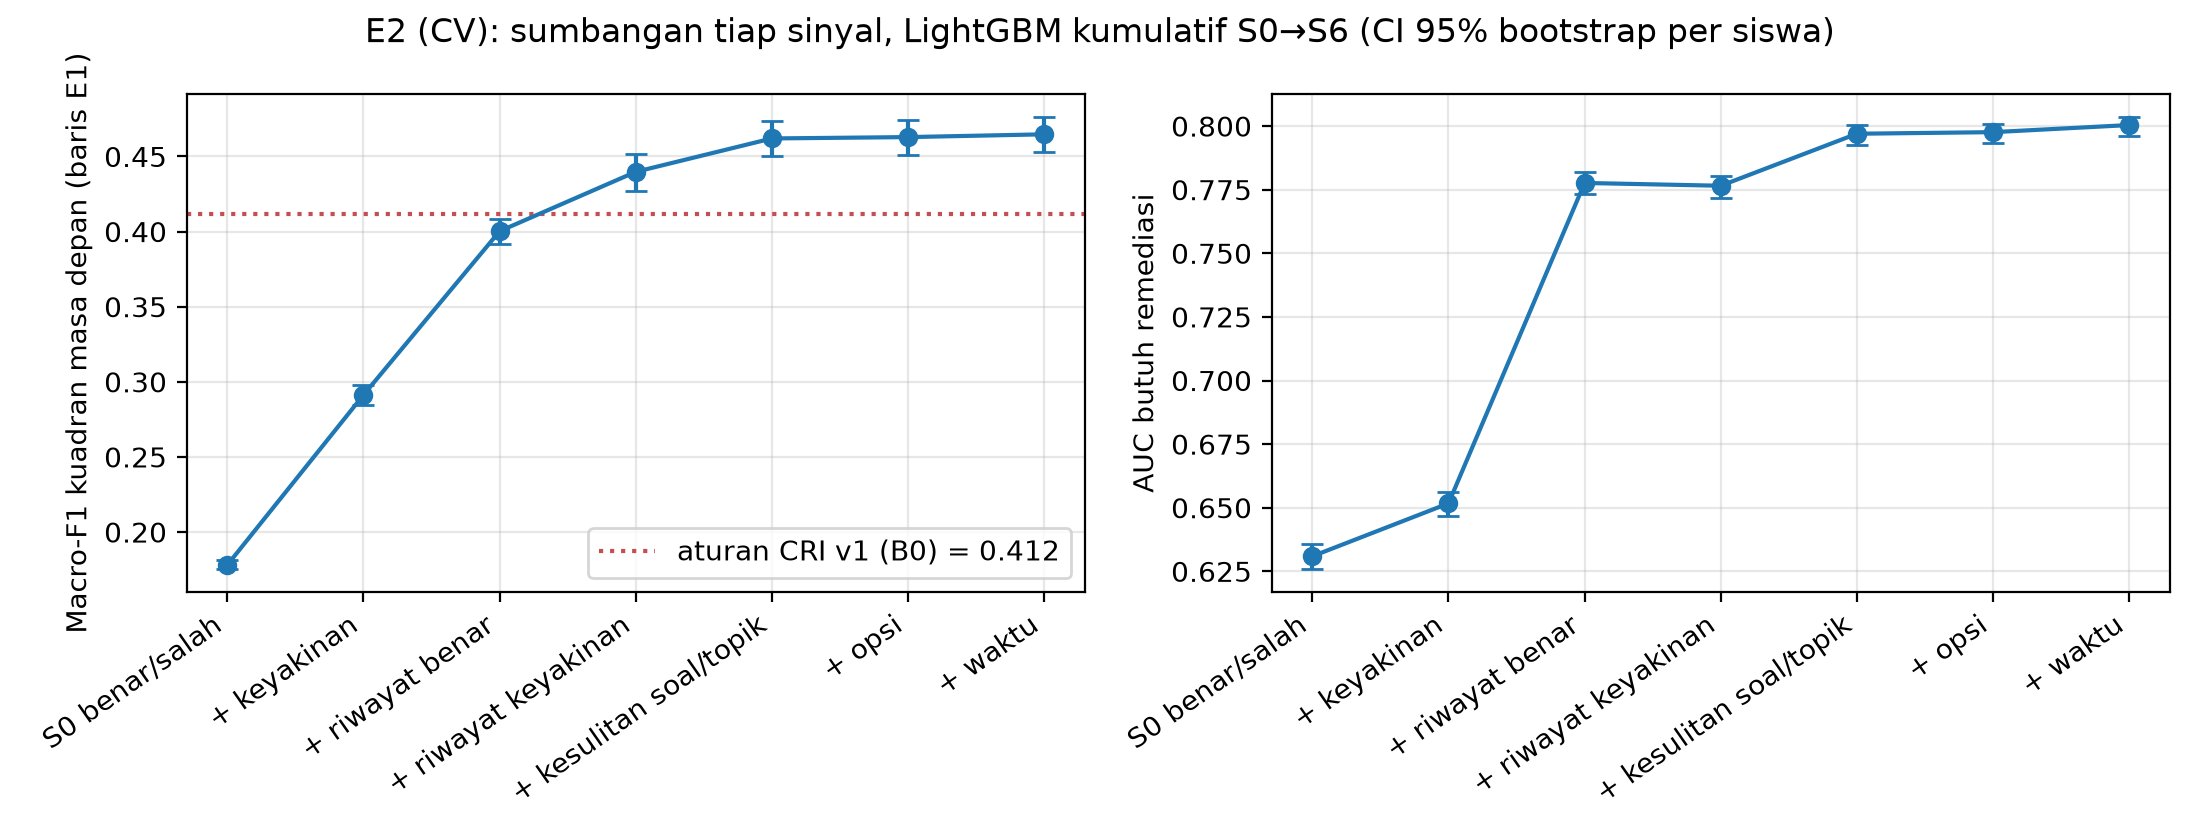

In [6]:
display(Image(FIGURES / 'E2_ablation.png', width=640))

# ## Interpretasi: SHAP dan tiga alasan Bahasa Indonesia (`l1.explain`)

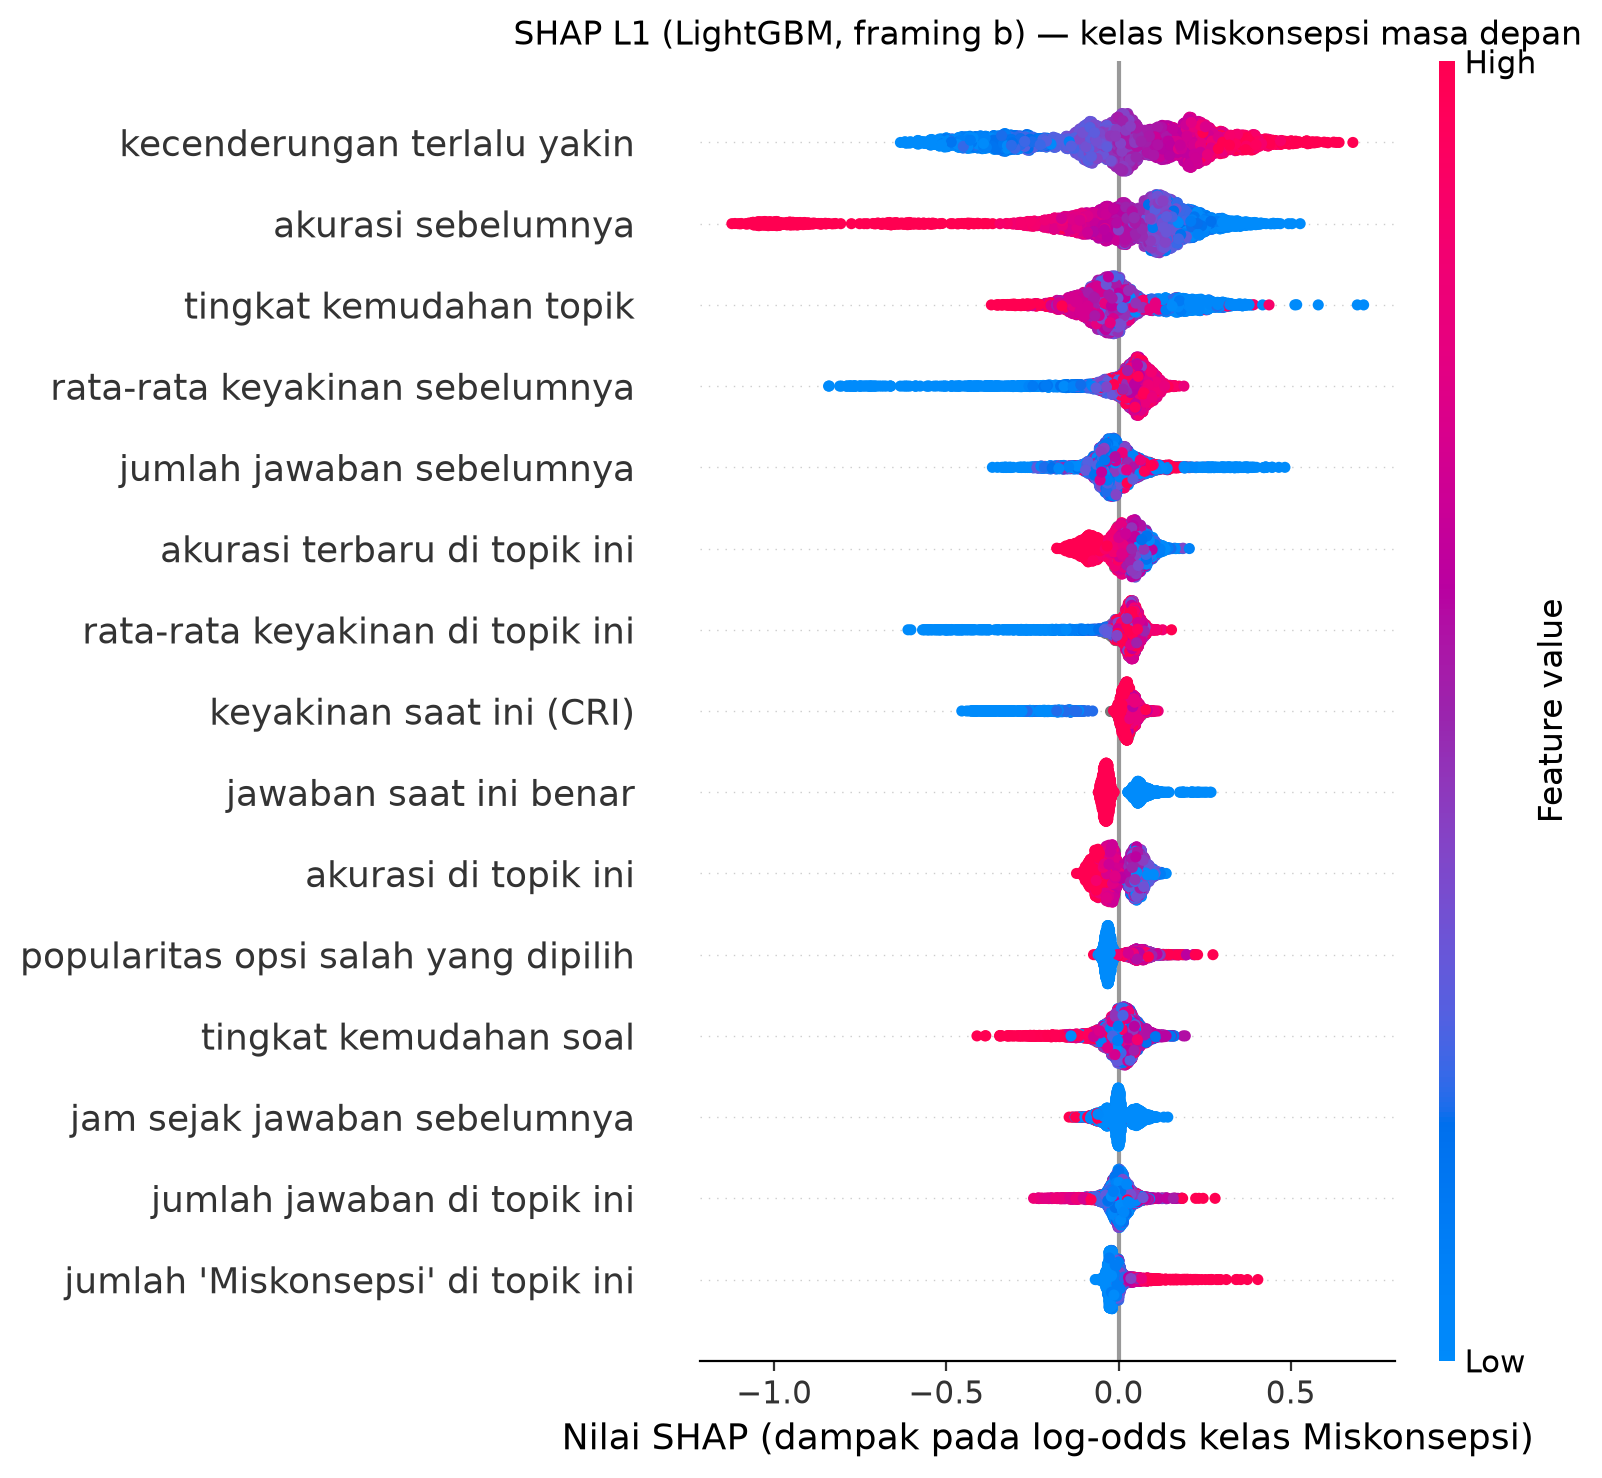

In [7]:
display(Image(FIGURES / 'L1_shap_beeswarm.png', width=640))

In [8]:
import json
import lightgbm as lgb
from remediaide_ml.l1.common import iter_folds, load
from remediaide_ml.l1.explain import explain
from remediaide_ml.paths import MODELS
info = json.loads((MODELS / 'l1_features_v1.json').read_text())
booster = lgb.Booster(model_file=str(MODELS / 'l1_lgbm_v1' / info['models']['bbin'][0]))
# fold-0 model explains fold-0 validation rows (never seen in training); OOF encodings built inside the fold
_, d, tr, va = next(iter_folds(load('b'), folds=[0]))
dv = d.iloc[va]
sample = dv[dv.has_conf].sample(3, random_state=20261118)[info['features']]
for reasons in explain(booster, sample, k=3):
    print(reasons)

[{'feature': 'cur_correct', 'text': 'jawaban saat ini salah', 'impact': 0.294}, {'feature': 'ewm_acc_kc', 'text': 'akurasi terbaru di topik ini 100%', 'impact': -0.246}, {'feature': 'n_prev_kc', 'text': 'sudah 1 soal di topik ini', 'impact': 0.1514}]
[{'feature': 'kc_diff_oof', 'text': 'topik ini dijawab benar oleh 49% siswa', 'impact': 0.6157}, {'feature': 'acc_prev', 'text': 'akurasi keseluruhan sejauh ini 53%', 'impact': 0.3628}, {'feature': 'n_prev', 'text': 'sudah 549 soal dikerjakan', 'impact': 0.1592}]
[{'feature': 'acc_prev', 'text': 'akurasi keseluruhan sejauh ini 52%', 'impact': 0.2535}, {'feature': 'cur_correct', 'text': 'jawaban saat ini salah', 'impact': 0.1672}, {'feature': 'cur_cri', 'text': 'keyakinan saat ini 4 dari 5 (tinggi)', 'impact': -0.1586}]


# ## Pemilihan model (D-15 → D-18)

In [9]:
pd.read_csv(TABLES / 'L1_model_selection.csv')

,metrik,cokt,lgbm,selisih_cokt_minus_lgbm,ci_lo,ci_hi,seri,n_baris,n_siswa,catatan
0,salah kelompok,0.3470,0.3583,-0.0112,-0.0129,-0.0095,False,217480,3054,CO-KT ensemble 5 seed vs LightGBM ensemble 5 seed
1,macro-F1,0.4798,0.4654,0.0144,0.0105,0.0183,False,217480,3054,CO-KT ensemble 5 seed vs LightGBM ensemble 5 seed
